We start with looking at the data: it is now split in three target categories (classes): low, medium, and high grade at the final exam (Low: below 3.5, Medium: 3.5 to 4.5, High: 4.5 and above).

Original dataset size: 16
Augmented dataset size: 160
Students per category: {'Low': 24, 'Medium': 60, 'High': 76}


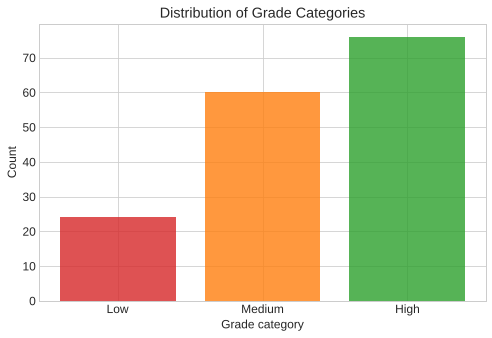

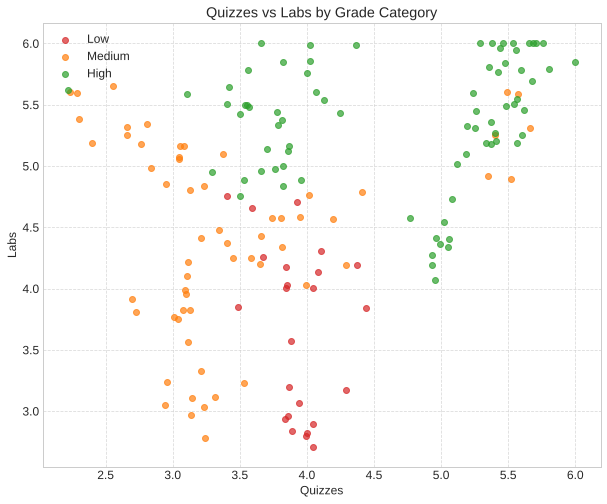

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

# Set the style for better-looking plots
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 12

# 1. Create the dataset
data = {
    'Quizzes': [5.3, 5.5, 5.5, 5.0, 2.5, 3.0, 3.0, 3.1, 3.5, 3.5, 3.7, 4.0, 4.0, 4.0, 4.0, 5.7],
    'Labs': [5.3, 5.9, 5.29, 4.35, 5.5, 5.0, 4.0, 3.1, 4.5, 5.62, 5.0, 3.0, 4.0, 5.75, 4.44, 5.9],
    'Final': [4.818, 5.773, 4.464, 5.069, 4.164, 4.091, 3.727, 3.909, 3.518, 4.897, 5.209, 3.0, 3.091, 5.818, 4.069, 5.77]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Augmenting data by replicating and adding noise
np.random.seed(42)
augmented = []
for i in range(len(df)):
    row = df.iloc[i]
    for _ in range(10):  # Create 10 variations of each record
        noise = np.random.normal(0, 0.2, 3)  # Add Gaussian noise
        new_row = row + noise
        # Ensure values are within boundaries
        new_row = new_row.clip(2, 6)
        augmented.append(new_row)

# Create augmented DataFrame
df_aug = pd.DataFrame(augmented, columns=df.columns)
print(f"Original dataset size: {len(df)}")
print(f"Augmented dataset size: {len(df_aug)}")

# Create grade categories for multi-class classification
def grade_to_category(grade):
    if grade < 3.5:
        return 0  # 'Low'
    elif grade < 4.5:
        return 1  # 'Medium'
    else:
        return 2  # 'High'

# Apply the function to create categorical grades
df_aug['Grade_Category'] = df_aug['Final'].apply(grade_to_category)

# Define labels and colors for visualization (Low / Medium / High = red / orange / green, as in the lecture)
grade_labels = ['Low', 'Medium', 'High']
grade_colors = ['tab:red', 'tab:orange', 'tab:green']

# Visualize the distribution of grade categories
counts = df_aug['Grade_Category'].value_counts().sort_index()
print("Students per category:", {label: int(n) for label, n in zip(grade_labels, counts.values)})
fig1 = plt.figure(figsize=(8, 5))
plt.bar(range(3), counts.values, color=grade_colors, alpha=0.8)
plt.xticks(range(3), grade_labels)
plt.title('Distribution of Grade Categories')
plt.xlabel('Grade category')
plt.ylabel('Count')
plt.show()

# Visualize the data with respect to the features
fig2 = plt.figure(figsize=(10, 8))
for category in range(3):
    subset = df_aug[df_aug['Grade_Category'] == category]
    plt.scatter(subset['Quizzes'], subset['Labs'], label=grade_labels[category], color=grade_colors[category], alpha=0.7)
plt.title('Quizzes vs Labs by Grade Category')
plt.xlabel('Quizzes')
plt.ylabel('Labs')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

**Reading the result:** the 160 students split into 24 Low, 60 Medium, and 76 High, so the classes are unbalanced and Low is the smallest. In the scatter plot, Low students cluster around a quiz score of 4 with lab scores below about 4.8, Medium students mostly have quiz scores below 3.5, and High students have high lab scores or high quiz scores. The groups overlap, and no straight line separates one category from the other two without errors.

We want to predict for every sample, the right assignment in one of the three classes, given the features Labs and Quizzes. 
We start with logistic regression for many classes, using the One-vs-All approach (sigmoid for each of the three models). This corresponds to having three separate models, one for each class: High vs (Medium, Low); Medium vs (High, Low); and Low vs (High, Medium). But we also run in parallel softmax regression. We will compare the resulting probabilities (sigmoid vs softmax).

## One-vs-All (one-vs-rest): three independent classifiers, and softmax regression

One binary logistic model per class on the two features. Each model outputs its own probability for its class against the rest. Softmax regression is trained on the same data: one model with one linear predictor per class.

In [2]:

X = df_aug[['Quizzes', 'Labs']].values
y = df_aug['Grade_Category'].values

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

class SoftmaxRegression:
    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
    
    def softmax(self, z):
        shifted_z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(shifted_z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.n_classes = len(np.unique(y))
        
        self.weights = np.random.randn(n_features, self.n_classes) * 0.01
        self.bias = np.zeros((1, self.n_classes))
        
        y_one_hot = np.zeros((n_samples, self.n_classes))
        y_one_hot[np.arange(n_samples), y] = 1
        
        for _ in range(self.epochs):
            linear_output = np.dot(X, self.weights) + self.bias
            y_pred = self.softmax(linear_output)
            
            dw = (1/n_samples) * np.dot(X.T, (y_pred - y_one_hot))
            db = (1/n_samples) * np.sum(y_pred - y_one_hot, axis=0, keepdims=True)
            
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
    
    def linear_predictor(self, X):
        return np.dot(X, self.weights) + self.bias
    
    def predict_proba(self, X):
        linear_output = self.linear_predictor(X)
        return self.softmax(linear_output)
    
    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

class BinaryLogisticRegression:
    # Logistic regression for one class against the rest, trained with gradient descent (L05)
    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
    
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    
    def fit(self, X, y_binary):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        for _ in range(self.epochs):
            y_hat = self.sigmoid(X @ self.weights + self.bias)
            self.weights -= self.learning_rate * (1/n_samples) * X.T @ (y_hat - y_binary)
            self.bias -= self.learning_rate * (1/n_samples) * np.sum(y_hat - y_binary)
    
    def linear_predictor(self, X):
        return X @ self.weights + self.bias
    
    def predict_proba(self, X):
        return self.sigmoid(self.linear_predictor(X))

# Train the softmax model
model = SoftmaxRegression(learning_rate=0.1, epochs=1000)
model.fit(X_train_scaled, y_train)

# Train the One-vs-All models: one binary classifier per class (class k = 1, all others = 0)
ova_models = []
for class_idx in range(len(grade_labels)):
    clf = BinaryLogisticRegression(learning_rate=0.1, epochs=1000)
    clf.fit(X_train_scaled, (y_train == class_idx).astype(int))
    ova_models.append(clf)

# Select 3 samples
sample_indices = [0, 5, 10]  # Use just 3 samples
sample_data = []

for idx in sample_indices:
    # Get features
    quiz_scaled = X_test_scaled[idx, 0]
    lab_scaled = X_test_scaled[idx, 1]
    
    # Get true class
    true_class = y_test[idx]
    true_label = grade_labels[true_class]
    
    # All three softmax probabilities for this sample (one model)
    softmax_probs = model.predict_proba(X_test_scaled[idx].reshape(1, -1))[0]
    softmax_z = model.linear_predictor(X_test_scaled[idx].reshape(1, -1))[0]
    
    # For each class
    for class_idx, class_name in enumerate(grade_labels):
        # One-vs-All: linear predictor and sigmoid of the binary model for this class
        x_sample = X_test_scaled[idx].reshape(1, -1)
        ova_z = ova_models[class_idx].linear_predictor(x_sample)[0]
        ova_sigmoid = ova_models[class_idx].predict_proba(x_sample)[0]
        
        sample_data.append({
            'Sample': idx + 1,
            'True Class': true_label,
            'Class': class_name,
            'Feature 1 (Quiz)': round(quiz_scaled, 2),
            'Feature 2 (Lab)': round(lab_scaled, 2),
            'z (One-vs-All)': round(ova_z, 2),
            'Sigmoid (One-vs-All)': round(ova_sigmoid, 3),
            'z (Softmax)': round(softmax_z[class_idx], 2),
            'Softmax Output': round(softmax_probs[class_idx], 3)
        })

# Create and display the table
results_df = pd.DataFrame(sample_data)

# Display the table in a cleaner format
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("\nFeature → Linear Predictor → Sigmoid (One-vs-All) / Softmax Output:\n")
print(results_df)

# Sum of the three probabilities per sample
sums = results_df.groupby('Sample')[['Sigmoid (One-vs-All)', 'Softmax Output']].sum().round(3)
print("\nSum over the three classes, per sample:")
print(sums)

# Show model parameters
weight_data = []
for i, class_name in enumerate(grade_labels):
    weight_data.append({
        'Class': class_name,
        'Weight (Quiz)': round(model.weights[0, i], 3),
        'Weight (Lab)': round(model.weights[1, i], 3),
        'Bias': round(model.bias[0, i], 3)
    })

weights_df = pd.DataFrame(weight_data)
print("\nSoftmax Model Weights and Biases:")
print(weights_df)

# Choose one sample to show detailed softmax calculation
sample_idx = 0  # First sample
linear_preds = model.linear_predictor(X_test_scaled[sample_idx].reshape(1, -1))[0]

print(f"\nDetailed Softmax Calculation for Sample {sample_idx+1}:")
print(f"Linear predictors: {np.round(linear_preds, 3)}")

# Step 1: Shift values for numerical stability
max_val = np.max(linear_preds)
shifted = linear_preds - max_val
print(f"Shifted values (for numerical stability): {np.round(shifted, 3)}")

# Step 2: Compute exponentials
exp_values = np.exp(shifted)
print(f"Exponential values: {np.round(exp_values, 3)}")

# Step 3: Normalize by sum
sum_exp = np.sum(exp_values)
softmax_values = exp_values / sum_exp
print(f"Sum of exponentials: {round(sum_exp, 3)}")
print(f"Softmax probabilities: {np.round(softmax_values, 3)}")
print(f"Sum of probabilities: {round(np.sum(softmax_values), 3)}")  # Should be 1.0


Feature → Linear Predictor → Sigmoid (One-vs-All) / Softmax Output:

   Sample True Class   Class  Feature 1 (Quiz)  Feature 2 (Lab)  z (One-vs-All)  Sigmoid (One-vs-All)  z (Softmax)  Softmax Output
0       1       High     Low             -0.35             0.46           -3.62                 0.026        -1.87           0.029
1       1       High  Medium             -0.35             0.46           -0.32                 0.420         0.81           0.427
2       1       High    High             -0.35             0.46            0.05                 0.512         1.06           0.544
3       6       High     Low              1.53             0.52           -2.28                 0.093        -1.15           0.030
4       6       High  Medium              1.53             0.52           -3.16                 0.041        -1.21           0.028
5       6       High    High              1.53             0.52            2.83                 0.944         2.30           0.942
6      11    

**Reading the result:** 
- **Sums:** each One-vs-All model is trained alone, so its sigmoid outputs do not have to add up to 1: for the three students the sums are 0.958, 1.078, and 1.049. The softmax outputs always sum to 1.
- **Predictions:** for these three students both approaches predict High, which is the true class. The probabilities differ, for example 0.512 (One-vs-All) and 0.544 (softmax) for High in sample 1.
- **Linear predictors:** the two `z` columns differ. Each One-vs-All `z` is the log-odds of one class against the rest (L05), while for softmax only the differences between the three `z` values matter.
- **Detailed calculation:** subtracting the largest `z` (1.056) before the exponential leaves the probabilities unchanged (lecture: QUESTION Softmax by Hand) and avoids overflow for large `z`.

Note that the three sigmoid probabilities do not add up to one (each is calculated by an independent one-vs-all model), but the three softmax probabilities do add up to 1 (they are calculated in the same model, which keeps the relationships between the data from different classes).

We will now proceed with comparing softmax regression to a neural network, on the same training and test split.

We will standardize the input features by subtracting the mean and dividing by the standard deviation for each feature dimension. Next, we define the softmax regression.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score


# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the Softmax Regression class
class SoftmaxRegression:
    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
    
    def softmax(self, z):
        # For numerical stability, subtract the maximum value
        shifted_z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(shifted_z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.n_classes = len(np.unique(y))
        
        # Initialize weights and bias
        self.weights = np.random.randn(n_features, self.n_classes) * 0.01
        self.bias = np.zeros((1, self.n_classes))
        
        # One-hot encode the target
        y_one_hot = np.zeros((n_samples, self.n_classes))
        y_one_hot[np.arange(n_samples), y] = 1
        
        # Training loop
        for _ in range(self.epochs):
            # Linear combination
            linear_output = np.dot(X, self.weights) + self.bias
            
            # Apply softmax activation
            y_pred = self.softmax(linear_output)
            
            # Compute gradients
            dw = (1/n_samples) * np.dot(X.T, (y_pred - y_one_hot))
            db = (1/n_samples) * np.sum(y_pred - y_one_hot, axis=0, keepdims=True)
            
            # Update parameters
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
    
    def predict_proba(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return self.softmax(linear_output)
    
    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

Next, we create the NN model. It is a very simple model with just one hidden layer. Note in the code below the parameters that you can already start changing: hidden_size (number of neurons), learning_rate, and epochs (corresponding to the number of gradient steps in this case). Moreover, you can add other hidden layers (then the weights and biases for each new layer need to be defined, initialized, and added to the training loop). When you run this cell multiple times, the results will change, because of the random initialization of the weights. Training longer (more epochs) reduces the part of this effect that comes from unfinished training, but it does not remove it: the cost of a neural network is non-convex, so different starting weights can end in different minima (lecture: Training Neural Networks). The training is done using *batch* gradient descent.

Training Softmax Regression with learning_rate=0.1, epochs=1000...
Training Neural Network with hidden_size=4, learning_rate=0.1, epochs=1000...
Softmax Regression: training accuracy 0.8047, test accuracy 0.7500
Neural Network:     training accuracy 0.8750, test accuracy 0.7812
Number of parameters of the network: 27


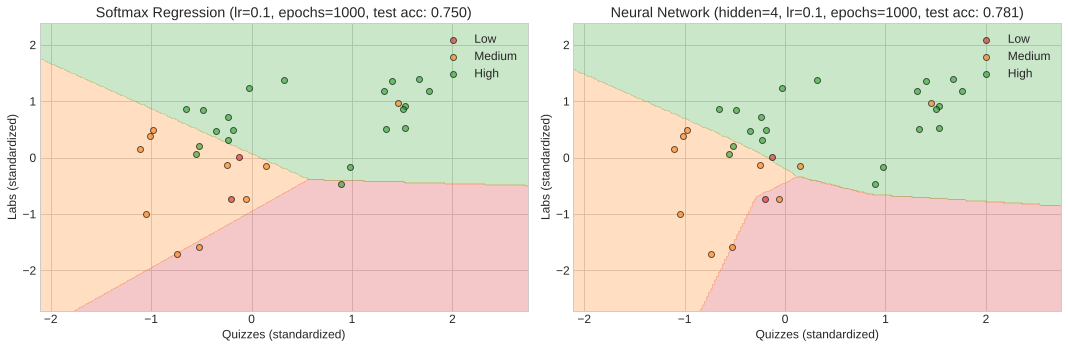

In [4]:

# Define the Neural Network class 
class NeuralNetwork:
    def __init__(self, hidden_size=4, learning_rate=0.1, epochs=1000):
        self.hidden_size = hidden_size
        self.learning_rate = learning_rate
        self.epochs = epochs
        
        # We have two sets of weights and biases:
        # 1. From input to hidden layer
        # 2. From hidden layer to output
        self.weights1 = None  # Input -> Hidden
        self.bias1 = None
        self.weights2 = None  # Hidden -> Output
        self.bias2 = None
    
    def relu(self, x):
        return np.maximum(0, x)
    
    def relu_derivative(self, x):
        return np.where(x > 0, 1.0, 0.0)
    
    def softmax(self, z):
        # For numerical stability, subtract the maximum value
        shifted_z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(shifted_z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.n_classes = len(np.unique(y))
        
        # Initialize weights and biases
        # Input -> Hidden
        self.weights1 = np.random.randn(n_features, self.hidden_size) * 0.01
        self.bias1 = np.zeros((1, self.hidden_size))
        
        # Hidden -> Output
        self.weights2 = np.random.randn(self.hidden_size, self.n_classes) * 0.01
        self.bias2 = np.zeros((1, self.n_classes))
        
        # One-hot encode the target
        y_one_hot = np.zeros((n_samples, self.n_classes))
        y_one_hot[np.arange(n_samples), y] = 1
        
        # Training loop
        for _ in range(self.epochs):
            # Forward pass
            # Input -> Hidden
            hidden_input = np.dot(X, self.weights1) + self.bias1
            hidden_output = self.relu(hidden_input)
            
            # Hidden -> Output
            output_input = np.dot(hidden_output, self.weights2) + self.bias2
            output_probs = self.softmax(output_input)
            
            # Backward pass (backpropagation)
            # Output layer gradients
            d_output = output_probs - y_one_hot
            
            # Hidden layer gradients
            d_weights2 = (1/n_samples) * np.dot(hidden_output.T, d_output)
            d_bias2 = (1/n_samples) * np.sum(d_output, axis=0, keepdims=True)
            
            d_hidden = np.dot(d_output, self.weights2.T) * self.relu_derivative(hidden_input)
            d_weights1 = (1/n_samples) * np.dot(X.T, d_hidden)
            d_bias1 = (1/n_samples) * np.sum(d_hidden, axis=0, keepdims=True)
            
            # Update parameters
            self.weights2 -= self.learning_rate * d_weights2
            self.bias2 -= self.learning_rate * d_bias2
            self.weights1 -= self.learning_rate * d_weights1
            self.bias1 -= self.learning_rate * d_bias1
    
    def forward(self, X):
        # Input -> Hidden
        hidden_input = np.dot(X, self.weights1) + self.bias1
        hidden_output = self.relu(hidden_input)
        
        # Hidden -> Output
        output_input = np.dot(hidden_output, self.weights2) + self.bias2
        output_probs = self.softmax(output_input)
        
        return hidden_output, output_probs
    
    def predict_proba(self, X):
        _, output_probs = self.forward(X)
        return output_probs
    
    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

# Train both models
softmax_params = {"learning_rate": 0.1, "epochs": 1000}
nn_params = {"hidden_size": 4, "learning_rate": 0.1, "epochs": 1000}

print(f"Training Softmax Regression with learning_rate={softmax_params['learning_rate']}, epochs={softmax_params['epochs']}...")
softmax_model = SoftmaxRegression(**softmax_params)
softmax_model.fit(X_train_scaled, y_train)

print(f"Training Neural Network with hidden_size={nn_params['hidden_size']}, learning_rate={nn_params['learning_rate']}, epochs={nn_params['epochs']}...")
nn_model = NeuralNetwork(**nn_params)
nn_model.fit(X_train_scaled, y_train)

# Evaluate both models
softmax_preds = softmax_model.predict(X_test_scaled)
nn_preds = nn_model.predict(X_test_scaled)

softmax_accuracy = accuracy_score(y_test, softmax_preds)
nn_accuracy = accuracy_score(y_test, nn_preds)

print(f"Softmax Regression: training accuracy {accuracy_score(y_train, softmax_model.predict(X_train_scaled)):.4f}, test accuracy {softmax_accuracy:.4f}")
print(f"Neural Network:     training accuracy {accuracy_score(y_train, nn_model.predict(X_train_scaled)):.4f}, test accuracy {nn_accuracy:.4f}")

# Number of parameters (weights and biases) of the network: 2*4 + 4 + 4*3 + 3 = 27 for hidden_size=4
n_params = nn_model.weights1.size + nn_model.bias1.size + nn_model.weights2.size + nn_model.bias2.size
print(f"Number of parameters of the network: {n_params}")

# Visualize the decision boundaries
def plot_decision_boundaries(models, X, y, titles):
    # Set up the meshgrid
    h = 0.02  # Step size in the mesh
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    
    # Create figure
    fig, axs = plt.subplots(1, len(models), figsize=(15, 5))
    
    for idx, (model, title) in enumerate(zip(models, titles)):
        # Predict class for each point in the meshgrid
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        # Plot decision boundary
        from matplotlib.colors import ListedColormap
        axs[idx].contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], alpha=0.25, cmap=ListedColormap(grade_colors))
        
        # Plot data points
        for i in range(len(grade_labels)):
            mask = (y == i)
            axs[idx].scatter(
                X[mask, 0], 
                X[mask, 1], 
                label=grade_labels[i],
                color=grade_colors[i],
                edgecolors='k', 
                alpha=0.6
            )
        
        axs[idx].set_title(title)
        axs[idx].set_xlabel('Quizzes (standardized)')
        axs[idx].set_ylabel('Labs (standardized)')
        axs[idx].legend()
    
    plt.tight_layout()
    plt.show()

# Create dynamic titles that reflect the actual parameters used
softmax_title = f'Softmax Regression (lr={softmax_params["learning_rate"]}, epochs={softmax_params["epochs"]}, test acc: {softmax_accuracy:.3f})'
nn_title = f'Neural Network (hidden={nn_params["hidden_size"]}, lr={nn_params["learning_rate"]}, epochs={nn_params["epochs"]}, test acc: {nn_accuracy:.3f})'

# Plot decision boundaries
plot_decision_boundaries(
    [softmax_model, nn_model], 
    X_test_scaled, 
    y_test, 
    [softmax_title, nn_title]
)

**Reading the result:** 
- **Softmax regression:** straight boundaries, training accuracy 0.80 and test accuracy 0.75.
- **Neural network:** training accuracy 0.875 and test accuracy 0.78, with 27 parameters, as counted in the lecture. With the default settings its boundaries bend only slightly: ReLU makes them piecewise straight, and 1000 epochs of batch gradient descent leave the network close to its start. With `epochs=5000` or more hidden neurons, the bends become clearer.
- **Test set:** it has 32 students (2 Low, 10 Medium, 20 High), so one student changes the accuracy by about 0.03: 0.75 against 0.78 is a single student. Rerunning this cell changes the network result, because the weights start at random values.

Notice the decision boundaries (change of color): for softmax regression, they are linear. This limits the expressivity or flexibility of the model. The reason for linear decision boundary is because of the linear predictor in the softmax (same for logistic regression).

The neural networks' decision boundary is nonlinear. This is because of the activation functions in each layer and neuron. This makes the model more flexible or expressive / adaptable to the data.

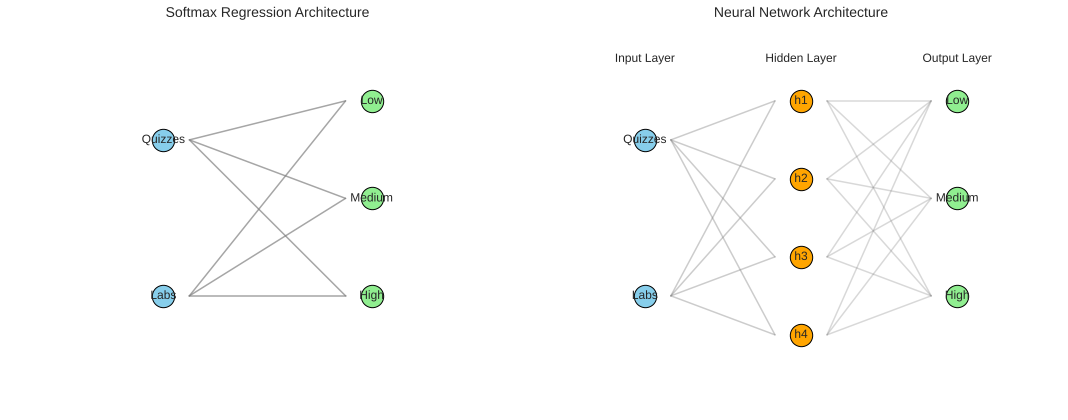

In [5]:
# Visualize the model architectures. The number of hidden units is taken from nn_params above.
def plot_model_architectures():
    fig, axs = plt.subplots(1, 2, figsize=(15, 6))
    
    # Softmax Regression architecture
    axs[0].set_xlim(0, 10)
    axs[0].set_ylim(0, 10)
    axs[0].axis('off')
    axs[0].set_title('Softmax Regression Architecture', fontsize=14)
    
    # Draw input nodes
    axs[0].scatter([3, 3], [7, 3], s=500, color='skyblue', edgecolor='black')
    axs[0].text(3, 7, 'Quizzes', ha='center', va='center')
    axs[0].text(3, 3, 'Labs', ha='center', va='center')
    
    # Draw output nodes
    for i, label in enumerate(grade_labels):
        y_pos = 8 - i * 2.5
        axs[0].scatter(7, y_pos, s=500, color='lightgreen', edgecolor='black')
        axs[0].text(7, y_pos, label, ha='center', va='center')
    
    # Draw connections
    for i, _ in enumerate(grade_labels):
        y_pos = 8 - i * 2.5
        axs[0].plot([3.5, 6.5], [7, y_pos], 'gray', alpha=0.7)
        axs[0].plot([3.5, 6.5], [3, y_pos], 'gray', alpha=0.7)
    
    # Neural Network architecture
    axs[1].set_xlim(0, 10)
    axs[1].set_ylim(0, 10)
    axs[1].axis('off')
    axs[1].set_title('Neural Network Architecture', fontsize=14)
    
    # Draw input nodes
    axs[1].scatter([2, 2], [7, 3], s=500, color='skyblue', edgecolor='black')
    axs[1].text(2, 7, 'Quizzes', ha='center', va='center')
    axs[1].text(2, 3, 'Labs', ha='center', va='center')
    
    # Draw hidden nodes
    n_hidden = nn_params['hidden_size']
    hidden_y = list(np.linspace(8, 2, n_hidden))
    for y_pos in hidden_y:
        axs[1].scatter(5, y_pos, s=500, color='orange', edgecolor='black')
        axs[1].text(5, y_pos, f'h{hidden_y.index(y_pos)+1}', ha='center', va='center')
    
    # Draw output nodes
    for i, label in enumerate(grade_labels):
        y_pos = 8 - i * 2.5
        axs[1].scatter(8, y_pos, s=500, color='lightgreen', edgecolor='black')
        axs[1].text(8, y_pos, label, ha='center', va='center')
    
    # Draw connections (input to hidden)
    for h_y in hidden_y:
        axs[1].plot([2.5, 4.5], [7, h_y], 'gray', alpha=0.4)
        axs[1].plot([2.5, 4.5], [3, h_y], 'gray', alpha=0.4)
    
    # Draw connections (hidden to output)
    for h_y in hidden_y:
        for i, _ in enumerate(grade_labels):
            y_pos = 8 - i * 2.5
            axs[1].plot([5.5, 7.5], [h_y, y_pos], 'gray', alpha=0.3)
    
    # Add labels for layers
    axs[1].text(2, 9, 'Input Layer', ha='center', fontsize=12)
    axs[1].text(5, 9, 'Hidden Layer', ha='center', fontsize=12)
    axs[1].text(8, 9, 'Output Layer', ha='center', fontsize=12)
    
    plt.tight_layout()
    plt.show()

# Plot the model architectures
plot_model_architectures()

## Comparing the two models with 5-fold cross-validation

The test set above has only 32 students, so one accuracy value is a noisy estimate. As in L06, we compare the two models with stratified 5-fold cross-validation, and we repeat it for 5 random initializations of the weights to see how much the network depends on its starting point.

In [6]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_softmax, cv_nn = [], []
for init in range(5):
    np.random.seed(init)  # a different random initialization of the weights in each repetition
    acc_s, acc_n = [], []
    for train_idx, val_idx in cv.split(X, y):
        sc = StandardScaler().fit(X[train_idx])  # scaler fit on the training folds only
        X_tr, X_val = sc.transform(X[train_idx]), sc.transform(X[val_idx])
        s_model = SoftmaxRegression(**softmax_params); s_model.fit(X_tr, y[train_idx])
        n_model = NeuralNetwork(**nn_params); n_model.fit(X_tr, y[train_idx])
        acc_s.append(accuracy_score(y[val_idx], s_model.predict(X_val)))
        acc_n.append(accuracy_score(y[val_idx], n_model.predict(X_val)))
    cv_softmax.append(np.mean(acc_s)); cv_nn.append(np.mean(acc_n))
    print(f"Initialization {init}: 5-fold accuracy softmax {np.mean(acc_s):.3f}, neural network {np.mean(acc_n):.3f}")

print(f"\nSoftmax regression: {min(cv_softmax):.2f} to {max(cv_softmax):.2f}")
print(f"Neural network:     {min(cv_nn):.2f} to {max(cv_nn):.2f}")

Initialization 0: 5-fold accuracy softmax 0.800, neural network 0.819
Initialization 1: 5-fold accuracy softmax 0.800, neural network 0.825
Initialization 2: 5-fold accuracy softmax 0.800, neural network 0.850
Initialization 3: 5-fold accuracy softmax 0.800, neural network 0.838
Initialization 4: 5-fold accuracy softmax 0.800, neural network 0.838

Softmax regression: 0.80 to 0.80
Neural network:     0.82 to 0.85


**Reading the result:** 
- **Softmax regression** gives 0.80 for every initialization: its cost is convex, so gradient descent ends in the same minimum from any start.
- **The neural network** gives 0.82 to 0.85, depending on the starting weights: its cost is non-convex, and each start can end in a different minimum.
- On average the network is better by about 0.03 (0.834 against 0.800). This is smaller than its advantage in training accuracy (0.875 against 0.80): part of what the network gains on the training data does not carry over to new students (L05, variance).